# 01 - Data Exploration & Cleaning

**Goal of the project:** predict how much gas (`U_SCM`) will be consumed **next month**, using the billing month and, optionally, the Unit, Region or Zone.

**Goal of this notebook:** understand the raw data, clean it, and turn the ~79,000 raw rows into small *monthly total* tables that the models in notebook 02 can learn from.

| Step | What we do |
|---|---|
| 1 | Import libraries |
| 2 | Load the dataset (and read its README sheet) |
| 3 | First look at the data |
| 4 | Understand the columns we need |
| 5 | Check data quality |
| 6 | Clean the data |
| 7 | Explore patterns with charts |
| 8 | Aggregate into monthly tables and save them |

## Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# a few display settings so tables and charts are easier to read
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## Step 2: Load the dataset

In [2]:
# This notebook lives inside /notebooks, so ".." takes us back to the project root
ROOT = Path("..")
RAW_FILE = ROOT / "data" / "raw" / "SALES_DATA_SAMPLE_24_MONTHS_SYNTHETIC.xlsx"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"

# make sure the output folders exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# the Excel workbook has more than one sheet - let's see what is inside
sheets = pd.read_excel(RAW_FILE, sheet_name=None)
for name, sheet in sheets.items():
    print(f"{name!r}: {sheet.shape[0]:,} rows x {sheet.shape[1]} columns")

'Combined 24 Months': 79,422 rows x 22 columns
'READ ME - Synthetic Data': 8 rows x 2 columns


The second sheet is a README written by whoever prepared the dataset. Let's read it before we trust the data.

In [3]:
readme = sheets["READ ME - Synthetic Data"]
for _, row in readme.iterrows():
    print(f"{row['Item']}: {row['Details']}\n")

Purpose: Practice dataset extended to 24 billing months for learning and testing a forecasting workflow.

Original period: 202407 to 202506 (July 2024 to June 2025) — original workbook data.

Synthetic period: 202507 to 202606 (July 2025 to June 2026) — artificially generated rows, not real company records.

Creation method: Each new month copies the corresponding month from the original year, retaining geographic and customer-category fields.

Variation: Selected numeric consumption/financial values varied by a random factor from 0.90 to 1.10. CONS and GDS varied slightly as non-negative integer counts. Exact zeros remain zero.

Important limitation: These are simulated values, not verified real gas consumption. They do not reflect actual future demand, weather, billing rules, or business changes.

Recommended use: Use only for practice, code testing, and prototyping. Do not present synthetic rows as real observations or use them as proof of real-world model accuracy.

Reproducibility

**Important takeaway:** only the first 12 months (Jul 2024 - Jun 2025) are original data. The last 12 months (Jul 2025 - Jun 2026) are *synthetic*: they are copies of the first year with every value randomly nudged by up to +/-10%. We will use all 24 months, but we must remember that results are for **practice only**.

In [4]:
# the main data is on the first sheet
df_raw = sheets["Combined 24 Months"]
print("Shape (rows, columns):", df_raw.shape)

Shape (rows, columns): (79422, 22)


## Step 3: First look at the data

In [5]:
df_raw.head()

,BILLING_MONTH,UNIT,REGION,ZONE,SUB_ZONE,AREA_DESCR,CUST_CL_CD,AREA,CONS,U_SCM,OTHER_CM,U_MMBTU,OTHER_MMBTU,GDS,ADJ_DR,ADJ_CR,LPS_CHARGED,GAS_CHARGES,OTHER_GAS_CHARGES,METER_RENT,GST,OTHER_GST
0,202410,Unit A - Karachi,Karachi Western,Hawksbay/SITE,Hawksbay/Site,Area 2110 - Sher Shah Block D Gulbai Village,IND,2110,6,46981.5344,0.0,1790.4142,0.0,0,0.00,-150000.00,0.00,3849390.55,0.0,2900.0,1163304.06,0.0
1,202410,Unit A - Karachi,Karachi Western,Hawksbay/SITE,Hawksbay/Site,Area 2110 - Sher Shah Block D Gulbai Village,IND,2110,1,0.0000,0.0,0.0000,0.0,0,1730367.13,-5956.35,-26210.96,42648.00,0.0,350.0,16769.22,0.0
2,202410,Unit A - Karachi,Karachi Western,Hawksbay/SITE,Hawksbay/Site,Area 2110 - Sher Shah Block D Gulbai Village,IND,2110,5,506145.1567,0.0,19248.1357,0.0,0,0.00,0.00,-0.01,41419031.77,0.0,3200.0,7699368.85,0.0
3,202410,Unit A - Karachi,Karachi Western,Hawksbay/SITE,Hawksbay/Site,Area 2110 - Sher Shah Block D Gulbai Village,IND,2110,2,5640.7624,0.0,214.9632,0.0,0,0.00,0.00,0.00,494245.08,0.0,1100.0,185553.17,0.0
4,202410,Unit A - Karachi,Karachi Western,Hawksbay/SITE,Hawksbay/Site,Area 2110 - Sher Shah Block D Gulbai Village,IND,2110,1,20990.6997,0.0,799.9323,0.0,0,1978241.37,0.00,0.00,1719854.45,0.0,500.0,309663.80,0.0


In [6]:
# column names, data types and non-null counts
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 79422 entries, 0 to 79421
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   BILLING_MONTH      79422 non-null  int64  
 1   UNIT               79422 non-null  str    
 2   REGION             79422 non-null  str    
 3   ZONE               79422 non-null  str    
 4   SUB_ZONE           79422 non-null  str    
 5   AREA_DESCR         79422 non-null  str    
 6   CUST_CL_CD         79422 non-null  str    
 7   AREA               79422 non-null  int64  
 8   CONS               79422 non-null  int64  
 9   U_SCM              79422 non-null  float64
 10  OTHER_CM           79422 non-null  float64
 11  U_MMBTU            79422 non-null  float64
 12  OTHER_MMBTU        79422 non-null  float64
 13  GDS                79422 non-null  int64  
 14  ADJ_DR             79422 non-null  float64
 15  ADJ_CR             79422 non-null  float64
 16  LPS_CHARGED        79422 non-null

## Step 4: Understand the columns we need

For this task we only need five columns:

| Role | Column |
|---|---|
| Input feature | `BILLING_MONTH` |
| Input feature | `UNIT` |
| Input feature | `REGION` |
| Input feature | `ZONE` |
| **Output (what we predict)** | `U_SCM` (gas volume) |

The other columns (sub-zone, area, charges, taxes, etc.) are not part of this task, so we will not use them.

In [7]:
# how many different values does each location column have?
df_raw[["UNIT", "REGION", "ZONE", "SUB_ZONE", "AREA"]].nunique()

UNIT          3
REGION        9
ZONE         49
SUB_ZONE     91
AREA        461
dtype: int64

In [8]:
# units and regions are few enough to list in full
print("Units  :", sorted(df_raw["UNIT"].unique()))
print("Regions:", sorted(df_raw["REGION"].unique()))

Units  : ['Unit A - Karachi', 'Unit B - Interior Sindh', 'Unit Q-Baluchistan']
Regions: ['Hyderabad', 'Karachi Central', 'Karachi Eastern', 'Karachi Western', 'Larkana', 'Mirpurkhas', 'Nawabshah', 'Quetta', 'Sukkur']


In [9]:
# Is there a hierarchy?  Unit > Region > Zone
# If every zone sits in exactly one region, and every region in exactly one unit, the answer is yes.
hierarchy = df_raw[["UNIT", "REGION", "ZONE"]].drop_duplicates()
print("Max regions per zone:", hierarchy.groupby("ZONE")["REGION"].nunique().max())
print("Max units per region:", hierarchy.groupby("REGION")["UNIT"].nunique().max())

# number of zones inside each unit / region
hierarchy.groupby(["UNIT", "REGION"])["ZONE"].nunique()

Max regions per zone: 1
Max units per region: 1


UNIT                     REGION         
Unit A - Karachi         Karachi Central    10
                         Karachi Eastern     4
                         Karachi Western     8
Unit B - Interior Sindh  Hyderabad           4
                         Larkana             3
                         Mirpurkhas          4
                         Nawabshah           3
                         Sukkur              4
Unit Q-Baluchistan       Quetta              9
Name: ZONE, dtype: int64

The hierarchy is clean. That means Unit, Region and Zone are three *levels of detail* of the same gas data, so we can forecast at any of them (and the totals will add up).

## Step 5: Check data quality

In [10]:
# 5.1 missing values
n_missing = int(df_raw.isna().sum().sum())
print("Total missing values:", n_missing)

Total missing values: 0


In [11]:
# 5.2 duplicate rows
duplicates = df_raw[df_raw.duplicated()]
print("Exact duplicate rows:", len(duplicates))
print("  ...of which have U_SCM = 0:", int((duplicates["U_SCM"] == 0).sum()))

Exact duplicate rows: 100
  ...of which have U_SCM = 0: 97


In [12]:
# 5.3 columns that never change carry no information
for col in df_raw.columns:
    if df_raw[col].nunique() == 1:
        print(f"{col} has only one value: {df_raw[col].iloc[0]!r}")

CUST_CL_CD has only one value: 'IND'


In [13]:
# 5.4 our target column, U_SCM
print(df_raw["U_SCM"].describe().round(2))

print()
print("Rows with U_SCM = 0:", int((df_raw["U_SCM"] == 0).sum()))
print("Rows with U_SCM < 0:", int((df_raw["U_SCM"] < 0).sum()))

neg_share = df_raw.loc[df_raw["U_SCM"] < 0, "U_SCM"].sum() / df_raw["U_SCM"].sum() * 100
print(f"The negative rows add up to {neg_share:.2f}% of the total gas volume")

count       79422.00
mean        99352.06
std       1014481.15
min      -1965833.14
25%           245.89
50%          3618.30
75%         29331.89
max      55375496.40
Name: U_SCM, dtype: float64



Rows with U_SCM = 0: 8162
Rows with U_SCM < 0: 472
The negative rows add up to -0.19% of the total gas volume


### What we found and what we will do

| Finding | Decision |
|---|---|
| No missing values | Nothing to fix |
| Exact duplicate rows (almost all with zero gas) | **Remove them** |
| `CUST_CL_CD` never changes | **Drop it** (it cannot help a model) |
| Zero values in `U_SCM` | **Keep** (zero usage is a valid value) |
| Small negative values in `U_SCM` | **Keep** (they look like billing corrections; we want *net* consumption) |
| `BILLING_MONTH` looks like `202410` | **Convert to a real date** |

## Step 6: Clean the data

In [14]:
df = df_raw.copy()          # work on a copy so the raw data stays untouched

# 6.1 remove exact duplicate rows
df = df.drop_duplicates()

# 6.2 drop the column that has only one value
df = df.drop(columns=["CUST_CL_CD"])

# 6.3 turn 202410 into a proper date (first day of that month)
df["DATE"] = pd.to_datetime(df["BILLING_MONTH"].astype(str), format="%Y%m")

print(f"Rows before cleaning: {len(df_raw):,}")
print(f"Rows after cleaning : {len(df):,}")
print("Months covered      :", df["DATE"].min().strftime("%b %Y"), "to", df["DATE"].max().strftime("%b %Y"),
      f"({df['DATE'].nunique()} months)")

Rows before cleaning: 79,422
Rows after cleaning : 79,322
Months covered      : Jul 2024 to Jun 2026 (24 months)


## Step 7: Explore patterns with charts

### 7.1 Total gas consumption per month

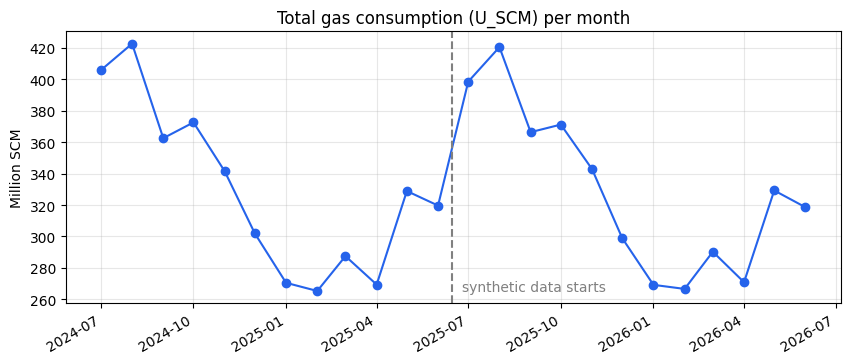

Highest month: Aug 2024 (422.5 M SCM)
Lowest month : Feb 2025 (265.4 M SCM)


In [15]:
# add up U_SCM for every month; divide by 1 million so the numbers are easier to read
monthly_total = df.groupby("DATE")["U_SCM"].sum() / 1e6

fig, ax = plt.subplots()
ax.plot(monthly_total.index, monthly_total.values, marker="o", color="#2563EB")

# mark where the synthetic data starts
ax.axvline(pd.Timestamp("2025-06-15"), color="grey", linestyle="--")
ax.text(pd.Timestamp("2025-06-25"), monthly_total.min(), "synthetic data starts", color="grey")

ax.set_title("Total gas consumption (U_SCM) per month")
ax.set_ylabel("Million SCM")
fig.autofmt_xdate()
fig.savefig(FIGURES_DIR / "monthly_total.png", dpi=130, bbox_inches="tight")
plt.show()

print(f"Highest month: {monthly_total.idxmax():%b %Y} ({monthly_total.max():.1f} M SCM)")
print(f"Lowest month : {monthly_total.idxmin():%b %Y} ({monthly_total.min():.1f} M SCM)")

There is a clear **seasonal pattern**: gas use is highest in the middle of the year and drops in winter. This is why the *month number* will be our most important feature.

### 7.2 Year 1 vs Year 2 (same calendar month)

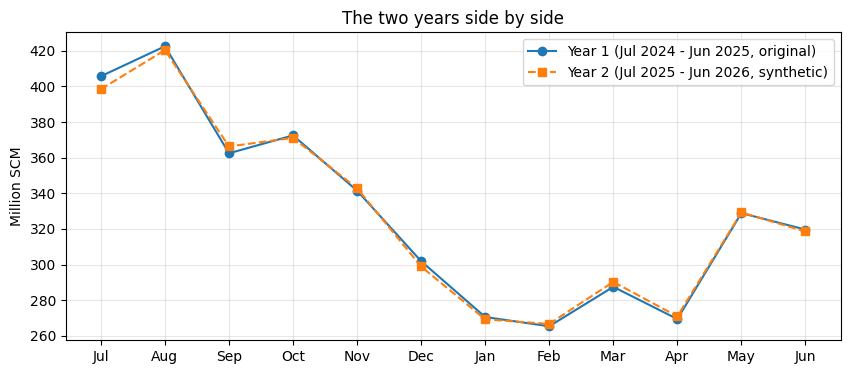

Year 2 / Year 1 for each month: min 0.982, max 1.011


In [16]:
year1 = monthly_total.iloc[:12]
year2 = monthly_total.iloc[12:]
month_names = year1.index.strftime("%b")

fig, ax = plt.subplots()
ax.plot(month_names, year1.values, marker="o", label="Year 1 (Jul 2024 - Jun 2025, original)")
ax.plot(month_names, year2.values, marker="s", linestyle="--", label="Year 2 (Jul 2025 - Jun 2026, synthetic)")
ax.set_title("The two years side by side")
ax.set_ylabel("Million SCM")
ax.legend()
plt.show()

ratio = year2.values / year1.values
print(f"Year 2 / Year 1 for each month: min {ratio.min():.3f}, max {ratio.max():.3f}")

The two years are almost identical (within about 2%), because year 2 was created from year 1. So models will find this data *easier* than real data would be. We will mention this again when we judge the results.

### 7.3 Which Units, Regions and Zones use the most gas?

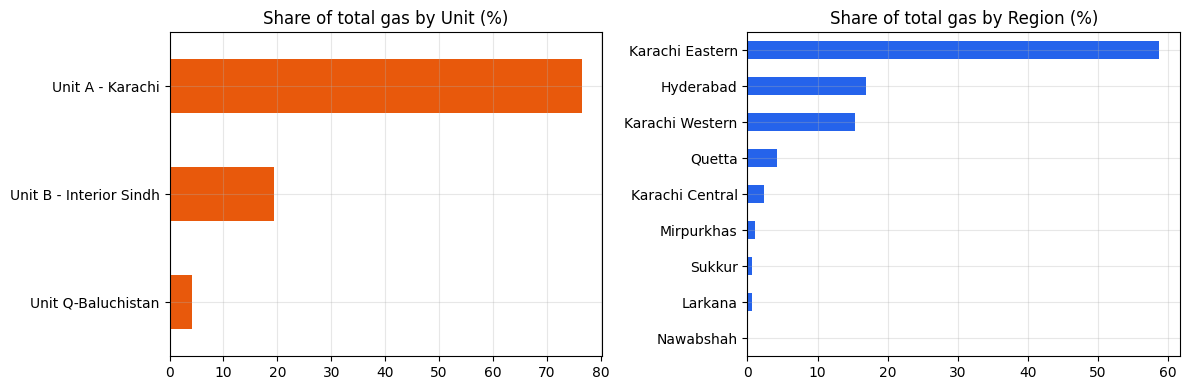

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

unit_share = df.groupby("UNIT")["U_SCM"].sum().sort_values()
(unit_share / unit_share.sum() * 100).plot(kind="barh", ax=axes[0], color="#E8590C")
axes[0].set_title("Share of total gas by Unit (%)")
axes[0].set_ylabel("")

region_share = df.groupby("REGION")["U_SCM"].sum().sort_values()
(region_share / region_share.sum() * 100).plot(kind="barh", ax=axes[1], color="#2563EB")
axes[1].set_title("Share of total gas by Region (%)")
axes[1].set_ylabel("")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "share_by_unit_region.png", dpi=130, bbox_inches="tight")
plt.show()

In [18]:
# zones: there are 49 of them, so let's look at the top 10 and how many are tiny
zone_share = df.groupby("ZONE")["U_SCM"].sum().sort_values(ascending=False)
zone_share = zone_share / zone_share.sum() * 100

print(zone_share.head(10).round(1).to_string())
print(f"\nZones with less than 0.5% of total gas: {(zone_share < 0.5).sum()} of {len(zone_share)}")

ZONE
Bin Qasim                            36.8
Kotri                                14.9
Landhi                               13.2
Hawksbay/SITE                        11.4
Korangi-I                             4.6
Korangi-II                            4.2
Hub                                   4.1
F.B.AREA                              2.2
Latifabad & SITE Area - Hyderabad     1.4
Maymar/Hijri                          1.3

Zones with less than 0.5% of total gas: 34 of 49


A few big units/regions/zones dominate the total, and many zones are tiny. Tiny zones are noisy, so **zone-level forecasts will be the hardest** to get right.

## Step 8: Aggregate into monthly tables

Right now one row = one billing record. But we want to predict *how much gas is used in a month*, so we **add up U_SCM** for each month. We do this at four levels:

| Level | What the table contains | Uses these inputs |
|---|---|---|
| `overall` | total gas per month | billing month only |
| `unit` | total gas per month per Unit | billing month + Unit |
| `region` | total gas per month per Region | billing month + Region |
| `zone` | total gas per month per Zone | billing month + Zone |

In [19]:
# the column used for grouping at each level (None = no grouping, just the month)
LEVELS = {"overall": None, "unit": "UNIT", "region": "REGION", "zone": "ZONE"}


def aggregate(data, group_col=None):
    """Add up U_SCM for each month (and each group). The result is in MILLIONS of SCM."""
    if group_col is None:
        out = data.groupby("DATE", as_index=False)["U_SCM"].sum()
    else:
        # unstack(fill_value=0) makes sure EVERY month/group pair exists (0 if no gas was billed)
        wide = data.groupby(["DATE", group_col])["U_SCM"].sum().unstack(fill_value=0)
        out = wide.reset_index().melt(id_vars="DATE", var_name=group_col, value_name="U_SCM")

    out["U_SCM"] = out["U_SCM"] / 1e6
    sort_cols = ["DATE"] + ([group_col] if group_col else [])
    return out.sort_values(sort_cols).reset_index(drop=True)


monthly_tables = {level: aggregate(df, col) for level, col in LEVELS.items()}

for level, table in monthly_tables.items():
    print(f"{level:8s} -> {table.shape[0]:5d} rows")

overall  ->    24 rows
unit     ->    72 rows
region   ->   216 rows
zone     ->  1176 rows


In [20]:
# a peek at the region table (9 regions x 24 months = 216 rows)
monthly_tables["region"].head(9)

,DATE,REGION,U_SCM
0,2024-07-01,Hyderabad,67.998411
1,2024-07-01,Karachi Central,8.780838
2,2024-07-01,Karachi Eastern,250.619288
3,2024-07-01,Karachi Western,53.630129
4,2024-07-01,Larkana,2.124793
5,2024-07-01,Mirpurkhas,4.463338
6,2024-07-01,Nawabshah,0.086450
7,2024-07-01,Quetta,15.486095
8,2024-07-01,Sukkur,2.463372


In [21]:
# Sanity check: the units/regions/zones should add up to the overall total for every month
overall = monthly_tables["overall"].set_index("DATE")["U_SCM"]

for level in ["unit", "region", "zone"]:
    summed = monthly_tables[level].groupby("DATE")["U_SCM"].sum()
    print(f"{level:7s} biggest difference vs overall: {(summed - overall).abs().max():.8f}")

# how many month/zone combinations had zero gas?
zone_table = monthly_tables["zone"]
print("\nZone-months with exactly zero gas:", int((zone_table["U_SCM"] == 0).sum()), "of", len(zone_table))

unit    biggest difference vs overall: 0.00000000
region  biggest difference vs overall: 0.00000000
zone    biggest difference vs overall: 0.00000000

Zone-months with exactly zero gas: 38 of 1176


In [22]:
# save the tables - notebook 02 and the app will read these files
file_names = {
    "overall": "monthly_overall.csv",
    "unit": "monthly_by_unit.csv",
    "region": "monthly_by_region.csv",
    "zone": "monthly_by_zone.csv",
}
for level, table in monthly_tables.items():
    table.to_csv(PROCESSED_DIR / file_names[level], index=False)
    print("saved", file_names[level])

saved monthly_overall.csv
saved monthly_by_unit.csv
saved monthly_by_region.csv
saved monthly_by_zone.csv


## Summary

* 79,422 raw rows -> 100 duplicates removed, one useless column dropped, billing month converted to a date.
* Gas consumption has a strong **seasonal pattern** (high mid-year, low in winter).
* Year 2 is a near-copy of year 1 (synthetic), so the data is easier than real data.
* We now have four small monthly tables (overall, unit, region, zone) saved in `data/processed/`.